<a href="https://colab.research.google.com/github/MilaniS-sudo/ASR700-Robotics-Assignment/blob/main/component_a/question2/motion_planning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DIJKSTRA
Path length (steps): 18
Nodes explored: 86
Execution time (seconds): 0.00089

A*
Path length (steps): 18
Nodes explored: 84
Execution time (seconds): 0.000817


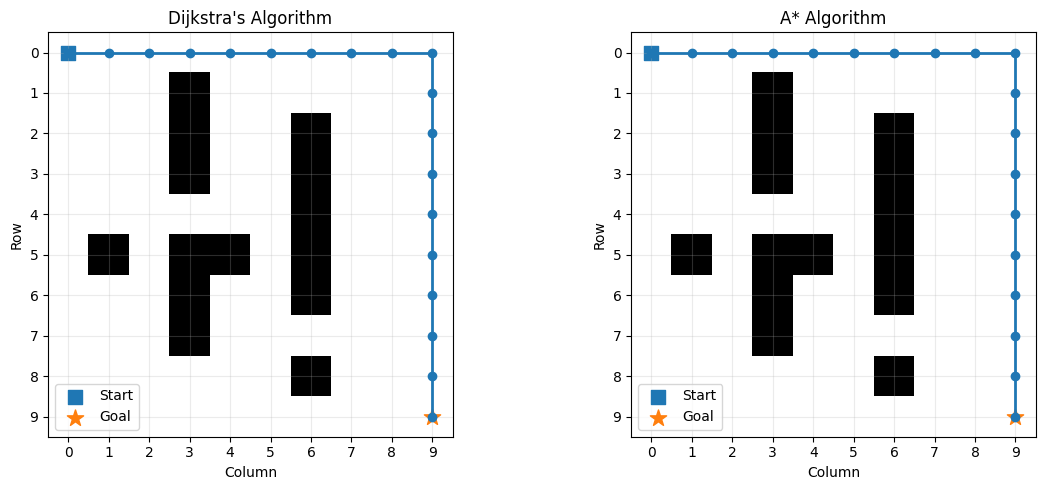

In [2]:

import heapq
import time
import numpy as np
import matplotlib.pyplot as plt


# 0 = free space, 1 = obstacle
grid = np.zeros((10, 10), dtype=int)

# Add obstacles to create a navigation environment.
grid[1:8, 3] = 1
grid[4, 3] = 0

grid[2:9, 6] = 1
grid[7, 6] = 0

grid[5, 1:5] = 1
grid[5, 2] = 0

START = (0, 0)
GOAL = (9, 9)


def get_neighbours(position):
    """Return valid up, down, left and right neighbours."""
    row, col = position
    candidates = [
        (row - 1, col),
        (row + 1, col),
        (row, col - 1),
        (row, col + 1)
    ]

    valid = []

    for r, c in candidates:
        if (0 <= r < grid.shape[0]
                and 0 <= c < grid.shape[1]
                and grid[r, c] == 0):
            valid.append((r, c))

    return valid


def heuristic(position, goal):
    """Manhattan distance for four-direction movement."""
    return abs(position[0] - goal[0]) + abs(position[1] - goal[1])


def search(start, goal, use_astar=False):
    """Run Dijkstra (False) or A* (True)."""
    frontier = []
    initial_h = heuristic(start, goal) if use_astar else 0

    heapq.heappush(frontier, (initial_h, 0, start))

    distances = {start: 0}
    parents = {}
    explored = set()

    while frontier:
        priority, cost, current = heapq.heappop(frontier)

        # Ignore outdated entries in the priority queue.
        if cost != distances.get(current):
            continue

        if current in explored:
            continue

        explored.add(current)

        if current == goal:
            break

        for neighbour in get_neighbours(current):
            new_cost = cost + 1

            if new_cost < distances.get(neighbour, float("inf")):
                distances[neighbour] = new_cost
                parents[neighbour] = current

                h = heuristic(neighbour, goal) if use_astar else 0
                heapq.heappush(
                    frontier,
                    (new_cost + h, new_cost, neighbour)
                )

    if goal not in distances:
        return [], len(explored), float("inf")

    # Reconstruct the path from goal back to start.
    path = []
    current = goal

    while current != start:
        path.append(current)
        current = parents[current]

    path.append(start)
    path.reverse()

    return path, len(explored), distances[goal]


# Run and time Dijkstra.
start_time = time.perf_counter()
dijkstra_path, dijkstra_nodes, dijkstra_cost = search(
    START, GOAL, use_astar=False
)
dijkstra_time = time.perf_counter() - start_time

# Run and time A*.
start_time = time.perf_counter()
astar_path, astar_nodes, astar_cost = search(
    START, GOAL, use_astar=True
)
astar_time = time.perf_counter() - start_time


# Display results.
print("DIJKSTRA")
print("Path length (steps):", dijkstra_cost)
print("Nodes explored:", dijkstra_nodes)
print("Execution time (seconds):", round(dijkstra_time, 6))

print("\nA*")
print("Path length (steps):", astar_cost)
print("Nodes explored:", astar_nodes)
print("Execution time (seconds):", round(astar_time, 6))


# Visualise both paths.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

results = [
    (axes[0], dijkstra_path, "Dijkstra's Algorithm"),
    (axes[1], astar_path, "A* Algorithm")
]

for ax, path, title in results:
    ax.imshow(grid, cmap="Greys", origin="upper", vmin=0, vmax=1)

    if path:
        rows = [point[0] for point in path]
        cols = [point[1] for point in path]
        ax.plot(cols, rows, marker="o", linewidth=2)
    else:
        ax.set_title(title + " — No path found")

    ax.scatter(START[1], START[0], marker="s", s=100, label="Start")
    ax.scatter(GOAL[1], GOAL[0], marker="*", s=150, label="Goal")

    ax.set_title(title)
    ax.set_xticks(range(grid.shape[1]))
    ax.set_yticks(range(grid.shape[0]))
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    ax.grid(True, alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()


Comparison of Dijkstra’s Algorithm and A*

Dijkstra’s algorithm and A* were tested on the same 10 × 10 occupancy grid, where 0 represents free space and 1 represents an obstacle. Both algorithms found a path of 18 steps.

Dijkstra explored 86 nodes and recorded an execution time of 0.000890 seconds. A* explored 84 nodes and recorded an execution time of 0.000817 seconds. Therefore, A* explored two fewer nodes and was slightly faster in this run.

Both algorithms found paths of equal length. A* uses the Manhattan distance heuristic to guide its search toward the goal, whereas Dijkstra explores according to accumulated path cost. The results show a small efficiency advantage for A* in this test. Execution times may vary between runs, so the measured difference should not be treated as a universal result.

Limitation: These tests use a simulated occupancy grid in Python. The algorithms still need to be integrated and tested in Webots for the robot simulation.